# Experimento 15B: ponderación temporal del entrenamiento

**DMEyF 2026 · Experimentos Colaborativos · Grupo B (Fray Campos y Verónica Monzón)**

**Hipótesis B:** ponderar los meses del entrenamiento no mejora la ganancia respecto de no ponderar.

| Brazo | Pesos por mes |
| :--- | :--- |
| Baseline | $w = 1$ en todos los meses |
| Placebo (`exp_azar`) | pesos exponenciales asignados a los meses al azar |
| Invertido (`exp_invertido`) | más peso a los meses viejos (vida media de 6 meses) |

- **Unidad de análisis:** semilla primigenia (10, las mismas en todos los brazos).
- **Métrica primaria:** ganancia máxima suavizada del ensamble de 10 semillas en 202106 (media móvil centrada de 1001 envíos) y cantidad de envíos en el máximo.
- **Prueba:** Wilcoxon pareado exacto y bilateral, con corrección de Holm por familia (Bonferroni como referencia).

Este notebook lee el `resumen.csv` y la `curva_ganancia.csv` de cada corrida y no vuelve a entrenar modelos.

## 1. Preparación del entorno

El notebook corre en Python, y el código R va en celdas que empiezan con `%%R` (puente rpy2), así se puede conectar Google Drive.

1. Conecta Google Drive.
2. Activa las celdas `%%R`.
3. Instala los paquetes de R (hay que repetirlo en cada sesión de Colab).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%load_ext rpy2.ipython

In [3]:
%%R
install.packages(c("data.table", "ggplot2"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cran.rstudio.com/src/contrib/data.table_1.18.6.1.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/ggplot2_4.0.4.tar.gz'

The downloaded source packages are in
	‘/tmp/RtmpKchnIp/downloaded_packages’


## 2. Carga y control de las corridas

1. Limpia la memoria de R y carga `data.table` y `ggplot2`.
2. Define la carpeta base y abre el log de la corrida (`exp/resultados/logs/log_analisis_exp.txt`).
3. Lee el `resumen.csv` de cada carpeta `exp/15B_<brazo>_<semilla>` y saca el brazo y la semilla primigenia del nombre de la carpeta.
4. Chequeo estructural: dimensiones, tipos de variables, corridas por brazo, cantidad de columnas del dataset (762 en todas) y faltantes.

In [4]:
%%R
rm(list = ls())

library(data.table)
library(ggplot2)

data.table 1.18.6.1 using 1 threads (see ?getDTthreads).  Latest news: r-datatable.com

Attaching package: ‘data.table’

The following object is masked from ‘package:base’:

    %notin%



In [5]:
%%R
dir_base <- "/content/drive/MyDrive/MDM/DM EyF/Experimentos colaborativos"

dir_log <- file.path(dir_base, "exp", "resultados", "logs")
dir.create(dir_log, showWarnings = FALSE, recursive = TRUE)

archivo_log <- file.path(dir_log, "log_analisis_exp.txt")
sink(archivo_log, split = TRUE)

cat("Corrida:", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), "\n")
print(sessionInfo())

Corrida: 2026-11-26 09:57:59 
R version 4.6.1 (2026-06-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 24.04.5 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/liblapack.so.3;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] tools     stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
[1] ggplot2_4.0.4       data.table_1.18.6.1

loaded via a namespace (and not attached):
 [1] RColorBrewer_1.1-3 R6_2.6.1           tidyselect_1.

In [6]:
%%R
dir_exp <- file.path(dir_base, "exp")

carpetas <- grep("^15B_",
                 list.dirs(dir_exp, recursive = FALSE, full.names = FALSE),
                 value = TRUE)

# lee el resumen.csv de una carpeta y agrega brazo y semilla primigenia a partir del nombre
leer_resumen <- function(carpeta) {
  r <- fread(file.path(dir_exp, carpeta, "resumen.csv"))
  partes <- strsplit(sub("^15B_", "", carpeta), "_")[[1]]
  r[, carpeta := carpeta]
  r[, brazo := paste(partes[-length(partes)], collapse = "_")]
  r[, semilla_primigenia := as.integer(partes[length(partes)])]
  r
}

lista_res <- lapply(carpetas, leer_resumen)
stopifnot(all(sapply(lista_res, nrow) == 1L))   # una fila por corrida

datos <- rbindlist(lista_res, use.names = TRUE, fill = TRUE)
print(length(carpetas))

[1] 40


In [7]:
%%R
print(dim(datos))
print(names(datos))
str(datos)
print(table(datos$brazo))        # corridas por brazo
print(table(datos$columnas))     # cantidad de columnas del dataset en cada corrida
print(colSums(is.na(datos)))     # faltantes por variable

[1] 40 11
 [1] "columnas"                "auc_validacion_BO"      
 [3] "auc_202106"              "num_iterations"         
 [5] "num_leaves"              "min_sum_hessian_in_leaf"
 [7] "ganancia_maxima"         "envios_en_el_maximo"    
 [9] "carpeta"                 "brazo"                  
[11] "semilla_primigenia"     
Classes ‘data.table’ and 'data.frame':	40 obs. of  11 variables:
 $ columnas               : int  762 762 762 762 762 762 762 762 762 762 ...
 $ auc_validacion_BO      : num  0.955 0.954 0.953 0.955 0.957 ...
 $ auc_202106             : num  0.931 0.93 0.93 0.93 0.93 ...
 $ num_iterations         : int  3931 3869 3835 3661 4059 3089 3195 3654 3705 3751 ...
 $ num_leaves             : int  1863 1479 1924 1780 1299 896 1750 1317 1730 1316 ...
 $ min_sum_hessian_in_leaf: num  0.0557 0.0113 0.0476 0.0549 0.0199 ...
 $ ganancia_maxima        : num  4.95e+08 4.94e+08 4.91e+08 4.87e+08 4.88e+08 ...
 $ envios_en_el_maximo    : int  13654 12044 13043 12658 13165 12468 13584 

## 3. Diseño: brazos, comparaciones y corridas disponibles

**Semillas primigenias:** 333331, 444443, 555557, 666667 y 121313 (Verónica); 700001, 700027, 700057, 700081 y 700099 (Fray). Son las mismas en todos los brazos.

**Comparaciones por familia** (diferencia = primer brazo menos segundo brazo, por primigenia):

| | Comparación | Pregunta |
| :--- | :--- | :--- |
| C1 | Placebo − Baseline | ¿Tener pesos desiguales, sin orden temporal, cambia la ganancia? |
| C2 | Invertido − Baseline | ¿Darle más peso a los meses viejos cambia la ganancia? |
| C3 | Placebo − Invertido | ¿Importa el orden temporal de los pesos? |

La segunda celda cuenta las primigenias de cada brazo. Una comparación se calcula solo cuando sus dos brazos tienen las 10. Hoy está completa la familia exponencial; la familia lineal queda pendiente.

In [8]:
%%R
semillas <- c(333331, 444443, 555557, 666667, 121313,
              700001, 700027, 700057, 700081, 700099)

# brazos esperados con su familia y su rol
brazos <- data.table(
  brazo   = c("baseline", "lineal_azar", "lineal_invertido", "exp_azar", "exp_invertido"),
  familia = c("base", "lineal", "lineal", "exponencial", "exponencial"),
  rol     = c("control", "placebo", "invertido", "placebo", "invertido")
)

# comparaciones pareadas por familia; diferencia = ganancia de brazo_x menos ganancia de brazo_y
comparaciones <- data.table(
  familia = rep(c("lineal", "exponencial"), each = 3),
  codigo  = rep(c("C1", "C2", "C3"), times = 2),
  brazo_x = c("lineal_azar", "lineal_invertido", "lineal_azar",
              "exp_azar", "exp_invertido", "exp_azar"),
  brazo_y = c("baseline", "baseline", "lineal_invertido",
              "baseline", "baseline", "exp_invertido")
)
print(comparaciones)

       familia codigo          brazo_x          brazo_y
        <char> <char>           <char>           <char>
1:      lineal     C1      lineal_azar         baseline
2:      lineal     C2 lineal_invertido         baseline
3:      lineal     C3      lineal_azar lineal_invertido
4: exponencial     C1         exp_azar         baseline
5: exponencial     C2    exp_invertido         baseline
6: exponencial     C3         exp_azar    exp_invertido


In [9]:
%%R
stopifnot(all(datos$semilla_primigenia %in% semillas))
stopifnot(all(datos$brazo %in% brazos$brazo))

disponibles <- datos[, .(n_primigenias = uniqueN(semilla_primigenia)), by = brazo]
estado <- merge(brazos, disponibles, by = "brazo", all.x = TRUE, sort = FALSE)
estado[is.na(n_primigenias), n_primigenias := 0L]
estado[, completo := n_primigenias == length(semillas)]
print(estado)

              brazo     familia       rol n_primigenias completo
             <char>      <char>    <char>         <int>   <lgcl>
1:         baseline        base   control            10     TRUE
2:      lineal_azar      lineal   placebo            10     TRUE
3: lineal_invertido      lineal invertido             0    FALSE
4:         exp_azar exponencial   placebo            10     TRUE
5:    exp_invertido exponencial invertido            10     TRUE


## 4. Comparaciones pareadas y prueba de Wilcoxon

1. **Tabla pareada:** una fila por semilla primigenia y una columna por brazo, con la ganancia en millones de pesos. Con ella se calcula la diferencia de cada comparación disponible, primigenia por primigenia.
2. **Wilcoxon de rangos con signo**, exacto y bilateral, sobre las 10 diferencias de cada comparación. Con 10 pares, el p exacto más chico posible es 2/2¹⁰ ≈ 0,002.
   - **Holm** corrige por las 3 comparaciones de cada familia ($\alpha = 0{,}05$). **Bonferroni** va como referencia.
   - **Lectura:** *mejora* (p ajustado < 0,05 y mediana de la diferencia positiva), *empeora* (p ajustado < 0,05 y mediana negativa) o *sin diferencia detectada* (p ajustado ≥ 0,05). "Sin diferencia detectada" no significa que los brazos rindan igual.

In [10]:
%%R
# metrica primaria: ganancia maxima suavizada del ensamble, en millones de pesos
datos[, ganancia_M := ganancia_maxima / 1e6]

# una fila por primigenia y una columna por brazo
ancha <- dcast(datos, semilla_primigenia ~ brazo, value.var = "ganancia_M")
setorder(ancha, semilla_primigenia)

brazos_completos <- estado[completo == TRUE, brazo]
stopifnot(!anyNA(ancha[, brazos_completos, with = FALSE]))
print(ancha)

# comparaciones que se pueden calcular hoy (los dos brazos con las 10 primigenias)
comparaciones[, disponible := brazo_x %in% brazos_completos & brazo_y %in% brazos_completos]
print(comparaciones)

# diferencias pareadas: ganancia de brazo_x menos ganancia de brazo_y, por primigenia
diferencias <- rbindlist(lapply(seq_len(nrow(comparaciones)), function(i) {
  cmp <- comparaciones[i]
  if (!cmp$disponible) return(NULL)
  data.table(familia            = cmp$familia,
             codigo             = cmp$codigo,
             brazo_x            = cmp$brazo_x,
             brazo_y            = cmp$brazo_y,
             semilla_primigenia = ancha$semilla_primigenia,
             delta_M            = ancha[[cmp$brazo_x]] - ancha[[cmp$brazo_y]])
}))
print(diferencias)

Key: <semilla_primigenia>
    semilla_primigenia baseline exp_azar exp_invertido lineal_azar
                 <int>    <num>    <num>         <num>       <num>
 1:             121313 494.8787 496.3797      500.1945    497.9877
 2:             333331 493.7340 487.5353      496.3634    494.6437
 3:             444443 491.1670 488.8034      495.2713    491.7628
 4:             555557 487.4303 490.9107      504.0613    490.3296
 5:             666667 488.3372 489.1233      493.7985    489.6500
 6:             700001 493.9970 489.9503      502.3511    497.2818
 7:             700027 499.7719 497.9954      505.7642    498.7338
 8:             700057 480.7391 482.5777      493.4394    482.8448
 9:             700081 492.6001 496.1087      504.3107    492.6108
10:             700099 486.8068 503.0688      503.9305    487.5748
       familia codigo          brazo_x          brazo_y disponible
        <char> <char>           <char>           <char>     <lgcl>
1:      lineal     C1      lineal_az

In [11]:
%%R
# prueba de rangos con signo sobre las diferencias pareadas de una comparacion
prueba_wilcoxon <- function(codigo_cmp, fam) {
  d <- diferencias[familia == fam & codigo == codigo_cmp, delta_M]
  w <- wilcox.test(d, mu = 0, exact = TRUE, alternative = "two.sided")
  data.table(familia     = fam,
             codigo      = codigo_cmp,
             n           = length(d),
             n_positivas = sum(d > 0),
             mediana_M   = median(d),
             media_M     = mean(d),
             V           = unname(w$statistic),
             p           = w$p.value)
}

disp <- comparaciones[disponible == TRUE, .(familia, codigo)]
resultados <- rbindlist(lapply(seq_len(nrow(disp)),
                               function(i) prueba_wilcoxon(disp$codigo[i], disp$familia[i])))

# Holm por familia, solo si las 3 comparaciones de la familia estan disponibles
familias_completas <- comparaciones[, .(todas = all(disponible)), by = familia][todas == TRUE, familia]
resultados[, p_holm := NA_real_]
resultados[, p_bonf := NA_real_]
resultados[familia %in% familias_completas, p_holm := p.adjust(p, method = "holm"), by = familia]
resultados[familia %in% familias_completas, p_bonf := p.adjust(p, method = "bonferroni"), by = familia]

# lectura segun el README: mejora / empeora / sin diferencia detectada (alfa = 0.05)
resultados[, ajuste := fifelse(is.na(p_holm), "provisional (sin Holm)", "Holm")]
resultados[, p_usado := fifelse(is.na(p_holm), p, p_holm)]
resultados[, lectura := fifelse(p_usado < 0.05 & mediana_M > 0, "mejora",
                        fifelse(p_usado < 0.05 & mediana_M < 0, "empeora",
                                "sin diferencia detectada"))]
print(resultados)


Index: <familia>
       familia codigo     n n_positivas mediana_M   media_M     V           p
        <char> <char> <int>       <int>     <num>     <num> <num>       <num>
1:      lineal     C1    10           9  1.111236  1.395777    50 0.019531250
2: exponencial     C1    10           6  1.143530  1.299137    30 0.845703125
3: exponencial     C2    10          10  7.173187  9.002286    55 0.001953125
4: exponencial     C3    10           0 -7.985385 -7.703148     0 0.001953125
        p_holm      p_bonf                 ajuste     p_usado
         <num>       <num>                 <char>       <num>
1:          NA          NA provisional (sin Holm) 0.019531250
2: 0.845703125 1.000000000                   Holm 0.845703125
3: 0.005859375 0.005859375                   Holm 0.005859375
4: 0.005859375 0.005859375                   Holm 0.005859375
                    lectura
                     <char>
1:                   mejora
2: sin diferencia detectada
3:                   mejora
4: 

## 5. Descriptivo por brazo y sensibilidad por origen del baseline

1. **Por brazo:** media, mediana, desvío, mínimo y máximo de la ganancia, mediana de la cantidad de envíos en el máximo y AUC media. La AUC es solo descriptiva: la comparación entre brazos se decide por la ganancia del ensamble.
2. **Por origen del baseline:** las diferencias pareadas separadas según quién corrió el baseline de cada primigenia (Verónica o Fray).
   - Los baselines de Fray salieron de otro flujo de ejecución (su notebook en Windows, con otras versiones de R y de los paquetes de la BO). Con las mismas filas, su BO evaluó otros 12 candidatos de hiperparámetros.
   - Por eso, en sus 5 primigenias, C1 y C2 difieren en los pesos y también en los candidatos de la BO. C3 queda limpia en las 10, porque sus dos brazos corrieron con el mismo script.

In [12]:
%%R
# descriptivo por brazo de la metrica primaria y de variables auxiliares
desc_brazo <- datos[, .(n                = .N,
                        gan_media_M      = mean(ganancia_M),
                        gan_mediana_M    = median(ganancia_M),
                        gan_sd_M         = sd(ganancia_M),
                        gan_min_M        = min(ganancia_M),
                        gan_max_M        = max(ganancia_M),
                        envios_mediana   = median(envios_en_el_maximo),
                        auc_202106_media = mean(auc_202106),
                        auc_BO_media     = mean(auc_validacion_BO)),
                    by = brazo]
desc_brazo <- desc_brazo[order(match(brazo, brazos$brazo))]
print(desc_brazo)

# sensibilidad: diferencias pareadas segun quien corrio el baseline de cada primigenia
semillas_vero <- c(333331, 444443, 555557, 666667, 121313)
diferencias[, origen_baseline := fifelse(semilla_primigenia %in% semillas_vero, "Vero", "Fray")]

desc_dif <- diferencias[, .(n           = .N,
                            n_positivas = sum(delta_M > 0),
                            mediana_M   = median(delta_M),
                            media_M     = mean(delta_M),
                            min_M       = min(delta_M),
                            max_M       = max(delta_M)),
                        by = .(familia, codigo, origen_baseline)]
print(desc_dif)

           brazo     n gan_media_M gan_mediana_M gan_sd_M gan_min_M gan_max_M
          <char> <int>       <num>         <num>    <num>     <num>     <num>
1:      baseline    10    490.9462      491.8835 5.309415  480.7391  499.7719
2:   lineal_azar    10    492.3420      492.1868 5.022801  482.8448  498.7338
3:      exp_azar    10    492.2453      490.4305 6.023287  482.5777  503.0688
4: exp_invertido    10    499.9485      501.2728 4.788591  493.4394  505.7642
   envios_mediana auc_202106_media auc_BO_media
            <num>            <num>        <num>
1:        12850.5        0.9301128    0.9542702
2:        12808.5        0.9301294    0.9542773
3:        12883.5        0.9299094    0.9512072
4:        12549.0        0.9305286    0.9509483
       familia codigo origen_baseline     n n_positivas  mediana_M    media_M
        <char> <char>          <char> <int>       <int>      <num>      <num>
1:      lineal     C1            Vero     5           5  1.3127473  1.7653297
2:      li

## 6. Hiperparámetros elegidos por la BO y control de bordes

La BO evalúa 12 combinaciones (diseño inicial de `mlr3mbo`, sin iteraciones bayesianas) y se queda con la de mayor AUC en validación. Rangos de búsqueda, iguales en todos los brazos:

| Hiperparámetro | Rango |
| :--- | :--- |
| `num_iterations` | 64 a 4096 |
| `num_leaves` | 16 a 2048 |
| `min_sum_hessian_in_leaf` | 0,000001 a 0,1 |

La celda resume los valores elegidos en cada brazo y marca las corridas cuyo ganador quedó en el 5% más cercano a un extremo del rango (umbral fijado por nosotras). Si el óptimo toca un borde, la comparación entre brazos puede estar midiendo los límites del rango. En este experimento no se amplió el rango ni se volvió a correr la BO: queda como limitación.

In [13]:
%%R
# rangos de busqueda de config_15B.yaml (iguales en todos los brazos)
bordes <- data.table(
  hiperparametro = c("num_iterations", "num_leaves", "min_sum_hessian_in_leaf"),
  inferior       = c(64, 16, 1e-06),
  superior       = c(4096, 2048, 0.1)
)

# una fila por corrida e hiperparametro, con el valor del mejor trial de la BO
hp_largo <- melt(datos[, .(brazo, semilla_primigenia,
                           num_iterations          = as.numeric(num_iterations),
                           num_leaves              = as.numeric(num_leaves),
                           min_sum_hessian_in_leaf)],
                 id.vars = c("brazo", "semilla_primigenia"),
                 measure.vars = bordes$hiperparametro,
                 variable.name = "hiperparametro", value.name = "valor",
                 variable.factor = FALSE)
hp_largo <- merge(hp_largo, bordes, by = "hiperparametro")

# posicion relativa dentro del rango: 0 = borde inferior, 1 = borde superior
hp_largo[, posicion := (valor - inferior) / (superior - inferior)]
hp_largo[, toca_borde := posicion <= 0.05 | posicion >= 0.95]

# resumen por brazo: valores elegidos y cuantas corridas quedaron contra un borde
desc_hp <- hp_largo[, .(mediana      = median(valor),
                        min          = min(valor),
                        max          = max(valor),
                        n_toca_borde = sum(toca_borde)),
                    by = .(brazo, hiperparametro)]
print(desc_hp)
print(hp_largo[toca_borde == TRUE, .(brazo, semilla_primigenia, hiperparametro, valor, posicion)])

            brazo          hiperparametro      mediana          min
           <char>                  <char>        <num>        <num>
 1:      baseline min_sum_hessian_in_leaf 3.329324e-02 7.303879e-03
 2:      exp_azar min_sum_hessian_in_leaf 4.841822e-02 1.125911e-02
 3: exp_invertido min_sum_hessian_in_leaf 5.208814e-02 1.125911e-02
 4:   lineal_azar min_sum_hessian_in_leaf 5.003555e-02 7.303879e-03
 5:      baseline          num_iterations 3.728000e+03 3.089000e+03
 6:      exp_azar          num_iterations 3.770000e+03 3.027000e+03
 7: exp_invertido          num_iterations 3.695000e+03 3.027000e+03
 8:   lineal_azar          num_iterations 3.695000e+03 3.089000e+03
 9:      baseline              num_leaves 1.604500e+03 8.960000e+02
10:      exp_azar              num_leaves 1.607500e+03 1.299000e+03
11: exp_invertido              num_leaves 1.662500e+03 1.369000e+03
12:   lineal_azar              num_leaves 1.592500e+03 8.960000e+02
             max n_toca_borde
           <num>  

## 7. Gráficos

Los PNG se guardan en `exp/resultados/plots/`.

1. **Ganancia pareada** (`01_ganancia_pareada.png`): la ganancia de cada primigenia en cada brazo. Cada línea gris une las corridas de una misma primigenia y la línea negra une las medianas.
2. **Diferencias pareadas** (`02_diferencias_pareadas.png`): un panel por comparación, con la diferencia de cada primigenia coloreada según quién corrió el baseline. La línea punteada roja es la mediana; a la derecha del cero gana el primer brazo.
3. **Curvas de ganancia suavizadas** (`03_curva_ganancia_suavizada.png`): la ganancia del ensamble según la cantidad de envíos, entre 8.000 y 16.000. Líneas finas: una por primigenia; línea gruesa: la media del brazo. Antes del gráfico, un control verifica que el máximo de cada curva reproduce la `ganancia_maxima` de su `resumen.csv`.
4. **Curva completa** (`03b_curva_ganancia_completa.png`): las mismas curvas en todo el rango de envíos, hasta 25.000. La zona gris marca el rango ampliado en el gráfico 3. Sirve para ver la forma de la curva: sube, llega al máximo y baja cuando los envíos extra ya no compensan su costo.

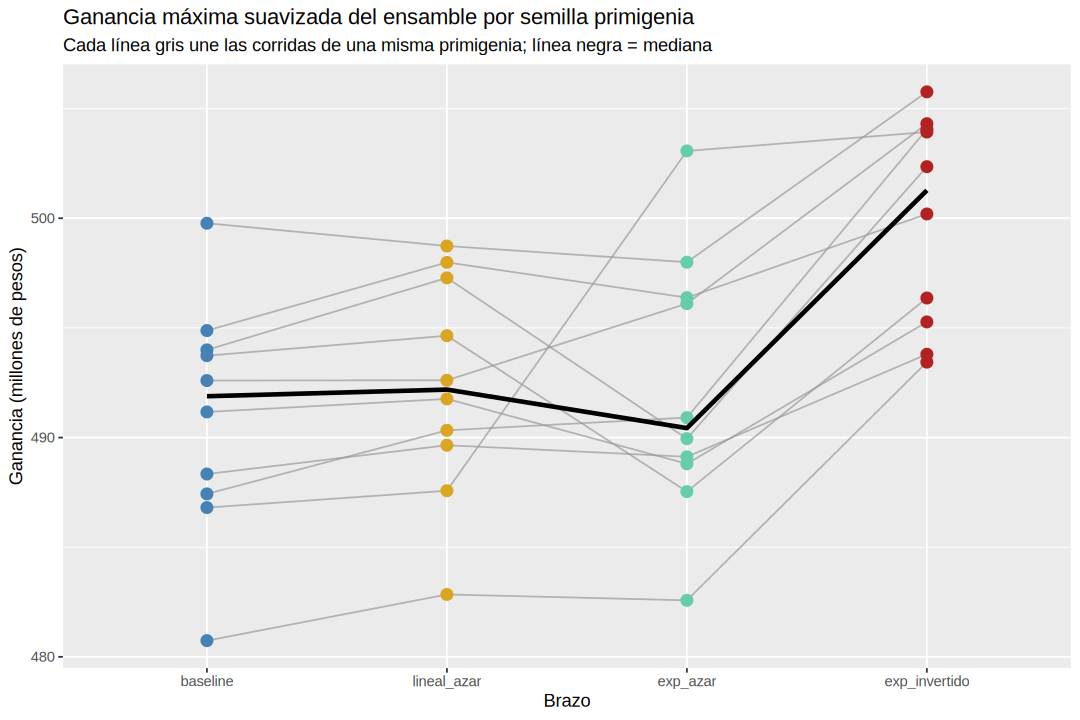

In [14]:
%%R -w 9 -h 6 --units in -r 120
dir_plots <- file.path(dir_base, "exp", "resultados", "plots")
dir.create(dir_plots, showWarnings = FALSE, recursive = TRUE)

# paleta por brazo y por origen del baseline
col_brazo  <- c(baseline = "steelblue", lineal_azar = "goldenrod", lineal_invertido = "coral2",
                exp_azar = "aquamarine3", exp_invertido = "firebrick")
col_origen <- c(Vero = "steelblue", Fray = "goldenrod")

# ---- Grafico 1: ganancia de cada primigenia en cada brazo (lineas = pares) ----
largo <- melt(ancha, id.vars = "semilla_primigenia", measure.vars = brazos_completos,
              variable.name = "brazo", value.name = "ganancia_M")
largo[, brazo := factor(brazo, levels = brazos$brazo[brazos$brazo %in% brazos_completos])]

g1 <- ggplot(largo, aes(x = brazo, y = ganancia_M)) +
  geom_line(aes(group = semilla_primigenia), color = "grey60", alpha = 0.7) +
  geom_point(aes(color = brazo), size = 3) +
  stat_summary(aes(group = 1), fun = median, geom = "line", color = "black", linewidth = 1.3) +
  scale_color_manual(values = col_brazo, guide = "none") +
  labs(title = "Ganancia máxima suavizada del ensamble por semilla primigenia",
       subtitle = "Cada línea gris une las corridas de una misma primigenia; línea negra = mediana",
       x = "Brazo", y = "Ganancia (millones de pesos)")
print(g1)
ggsave(file.path(dir_plots, "01_ganancia_pareada.png"), g1, width = 8, height = 6, dpi = 150)

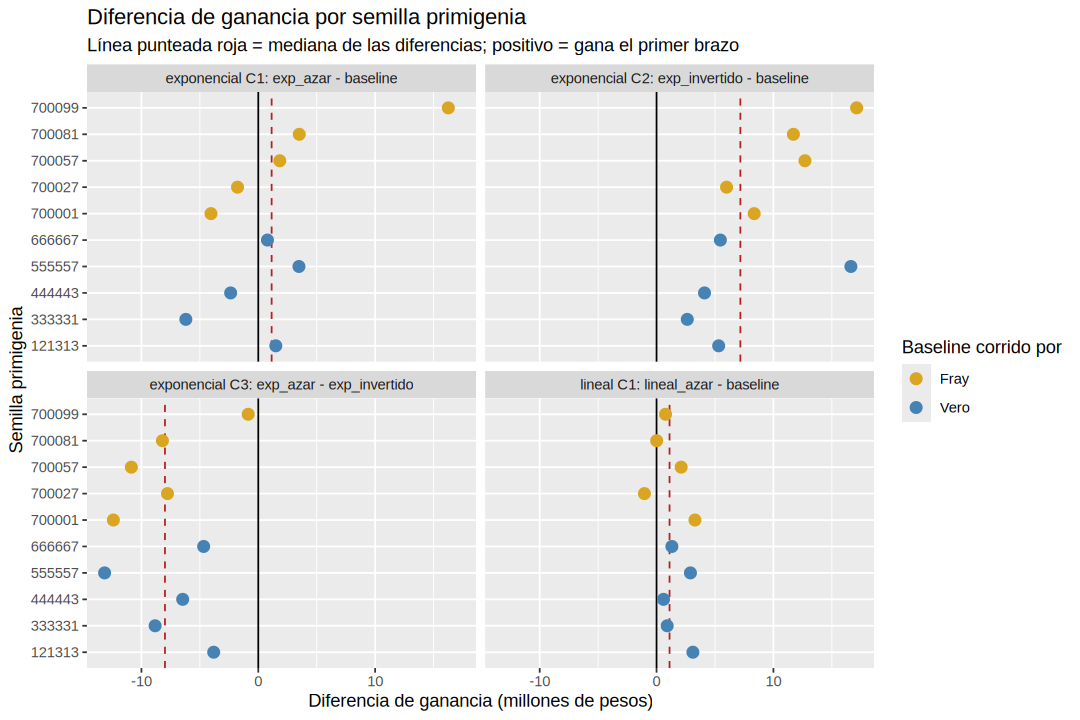

In [15]:
%%R -w 9 -h 6 --units in -r 120
diferencias[, comparacion := paste0(familia, " ", codigo, ": ", brazo_x, " - ", brazo_y)]
mediana_dif <- diferencias[, .(mediana_M = median(delta_M)), by = comparacion]

g2 <- ggplot(diferencias, aes(x = factor(semilla_primigenia), y = delta_M)) +
  geom_hline(yintercept = 0, color = "black") +
  geom_hline(data = mediana_dif, aes(yintercept = mediana_M),
             color = "firebrick", linetype = "dashed") +
  geom_point(aes(color = origen_baseline), size = 3) +
  scale_color_manual(values = col_origen, name = "Baseline corrido por") +
  coord_flip() +
  facet_wrap(~ comparacion) +
  labs(title = "Diferencia de ganancia por semilla primigenia",
       subtitle = "Línea punteada roja = mediana de las diferencias; positivo = gana el primer brazo",
       x = "Semilla primigenia", y = "Diferencia de ganancia (millones de pesos)")
print(g2)
ggsave(file.path(dir_plots, "02_diferencias_pareadas.png"), g2, width = 9, height = 6, dpi = 150)

[1] 320040      5
     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
0.000e+00 2.132e-13 2.558e-13 2.558e-13 2.984e-13 5.684e-13 


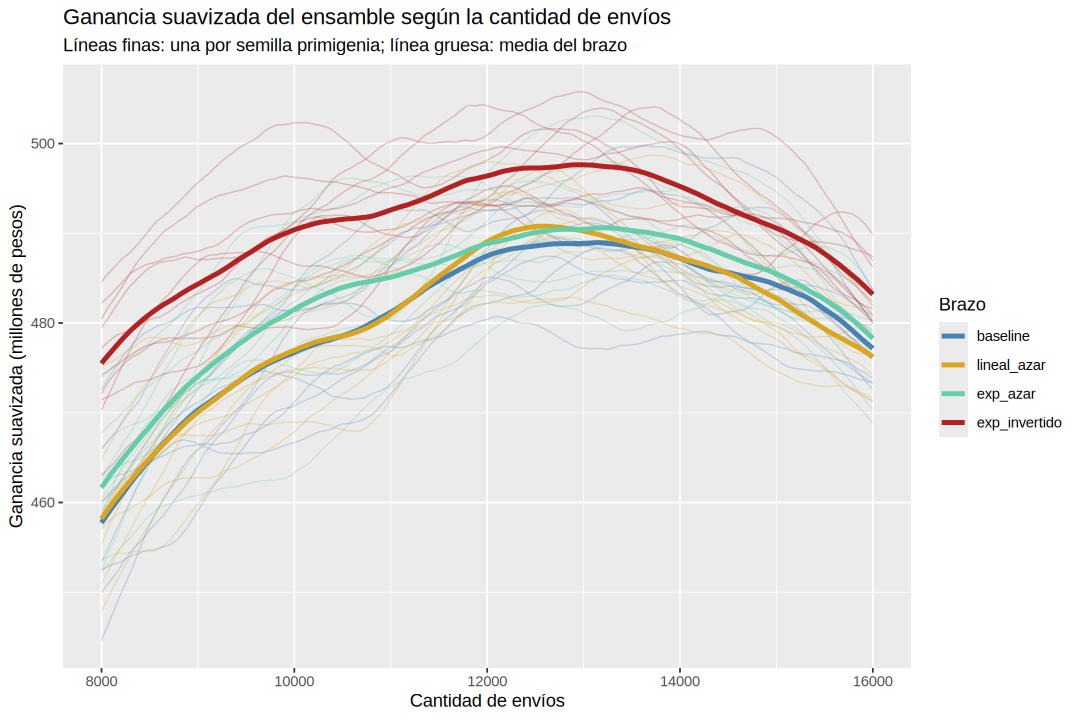

In [16]:
%%R -w 9 -h 6 --units in -r 120
# lee la curva de ganancia acumulada de una corrida, la suaviza con una media movil
# centrada de 1001 envios y se queda con la zona relevante de envios
leer_curva <- function(carpeta) {
  cv <- fread(file.path(dir_exp, carpeta, "curva_ganancia.csv"),
              select = c("pos", "ganancia_acumulada"))
  cv[, gan_suave_M := frollmean(ganancia_acumulada, n = 1001, align = "center") / 1e6]
  cv[, carpeta := carpeta]
  cv[pos >= 8000 & pos <= 16000, .(carpeta, pos, gan_suave_M)]
}

carpetas_curvas <- datos[brazo %in% brazos_completos, carpeta]
curvas <- rbindlist(lapply(carpetas_curvas, leer_curva))
curvas <- merge(curvas, datos[, .(carpeta, brazo, semilla_primigenia)], by = "carpeta")
curvas[, brazo := factor(brazo, levels = brazos$brazo[brazos$brazo %in% brazos_completos])]
print(dim(curvas))

# control: el maximo de cada curva suavizada debe reproducir ganancia_M de resumen.csv
control_max <- merge(curvas[, .(max_curva_M = max(gan_suave_M, na.rm = TRUE)), by = carpeta],
                     datos[, .(carpeta, ganancia_M)], by = "carpeta")
print(summary(abs(control_max$max_curva_M - control_max$ganancia_M)))

# media por brazo para cada cantidad de envios
media_brazo <- curvas[, .(gan_media_M = mean(gan_suave_M)), by = .(brazo, pos)]

g3 <- ggplot() +
  geom_line(data = curvas,
            aes(x = pos, y = gan_suave_M, color = brazo, group = carpeta),
            alpha = 0.25, linewidth = 0.4) +
  geom_line(data = media_brazo,
            aes(x = pos, y = gan_media_M, color = brazo),
            linewidth = 1.4) +
  scale_color_manual(values = col_brazo, name = "Brazo") +
  labs(title = "Ganancia suavizada del ensamble según la cantidad de envíos",
       subtitle = "Líneas finas: una por semilla primigenia; línea gruesa: media del brazo",
       x = "Cantidad de envíos", y = "Ganancia suavizada (millones de pesos)")
print(g3)
ggsave(file.path(dir_plots, "03_curva_ganancia_suavizada.png"), g3, width = 9, height = 6, dpi = 150)

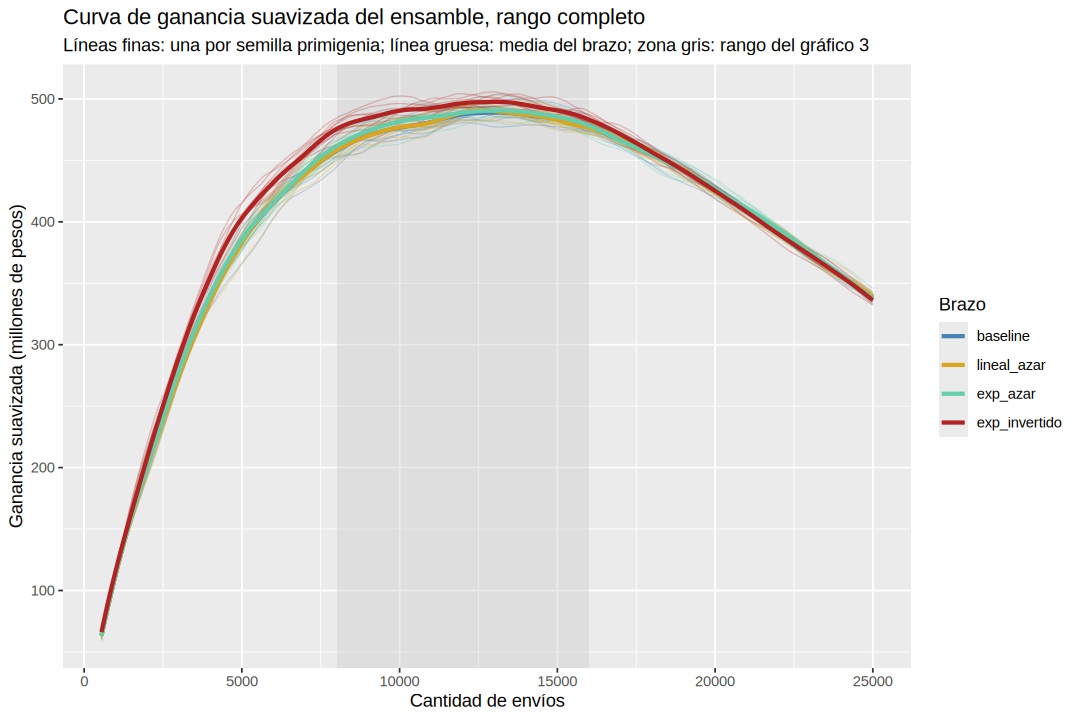

In [17]:
%%R -w 9 -h 6 --units in -r 120
# ---- Grafico 3 bis: curva de ganancia completa ----
max_envios <- 25000   # hasta cuantos envios se dibuja la curva

# lee la curva completa de una corrida, la suaviza igual que la metrica primaria
# y se queda con un punto cada 50 envios para que el grafico sea liviano
leer_curva_completa <- function(carpeta) {
  cv <- fread(file.path(dir_exp, carpeta, "curva_ganancia.csv"),
              select = c("pos", "ganancia_acumulada"))
  cv[, gan_suave_M := frollmean(ganancia_acumulada, n = 1001, align = "center") / 1e6]
  cv[, carpeta := carpeta]
  cv[pos <= max_envios & pos %% 50 == 0 & !is.na(gan_suave_M), .(carpeta, pos, gan_suave_M)]
}

curvas_completas <- rbindlist(lapply(carpetas_curvas, leer_curva_completa))
curvas_completas <- merge(curvas_completas, datos[, .(carpeta, brazo)], by = "carpeta")
curvas_completas[, brazo := factor(brazo, levels = levels(curvas$brazo))]

# media por brazo para cada cantidad de envios
media_completa <- curvas_completas[, .(gan_media_M = mean(gan_suave_M)), by = .(brazo, pos)]

g3b <- ggplot() +
  annotate("rect", xmin = 8000, xmax = 16000, ymin = -Inf, ymax = Inf,
           fill = "grey80", alpha = 0.4) +
  geom_line(data = curvas_completas,
            aes(x = pos, y = gan_suave_M, color = brazo, group = carpeta),
            alpha = 0.25, linewidth = 0.4) +
  geom_line(data = media_completa,
            aes(x = pos, y = gan_media_M, color = brazo),
            linewidth = 1.2) +
  scale_color_manual(values = col_brazo, name = "Brazo") +
  labs(title = "Curva de ganancia suavizada del ensamble, rango completo",
       subtitle = "Líneas finas: una por semilla primigenia; línea gruesa: media del brazo; zona gris: rango del gráfico 3",
       x = "Cantidad de envíos", y = "Ganancia suavizada (millones de pesos)")
print(g3b)
ggsave(file.path(dir_plots, "03b_curva_ganancia_completa.png"), g3b, width = 9, height = 6, dpi = 150)

## 8. Robustez por cantidad de envíos

Para no depender de un solo punto de la curva, se repite la comparación pareada en cortes fijos de envíos alrededor del máximo: 9.000, 10.000, 11.000, 12.000, 13.000, 14.000 y 15.000.

1. **Tabla:** para cada comparación y cada corte, cuántas primigenias dan diferencia positiva, la mediana y el rango de las diferencias.
2. **Gráfico** (`04_diferencias_por_envios.png`): la diferencia de cada primigenia a lo largo de los envíos (líneas grises) y su mediana (línea roja). Si la línea roja queda siempre del mismo lado del cero, el resultado no depende del corte elegido.

Es un análisis descriptivo: en los cortes no se hace prueba ni corrección por multiplicidad.

                                 comparacion envios     n n_positivas
                                      <char>  <int> <int>       <int>
 1:      exponencial C1: exp_azar - baseline   9000    10           7
 2:      exponencial C1: exp_azar - baseline  10000    10           8
 3:      exponencial C1: exp_azar - baseline  11000    10           7
 4:      exponencial C1: exp_azar - baseline  12000    10           7
 5:      exponencial C1: exp_azar - baseline  13000    10           6
 6:      exponencial C1: exp_azar - baseline  14000    10           8
 7:      exponencial C1: exp_azar - baseline  15000    10           6
 8: exponencial C2: exp_invertido - baseline   9000    10          10
 9: exponencial C2: exp_invertido - baseline  10000    10          10
10: exponencial C2: exp_invertido - baseline  11000    10          10
11: exponencial C2: exp_invertido - baseline  12000    10           9
12: exponencial C2: exp_invertido - baseline  13000    10          10
13: exponencial C2: 

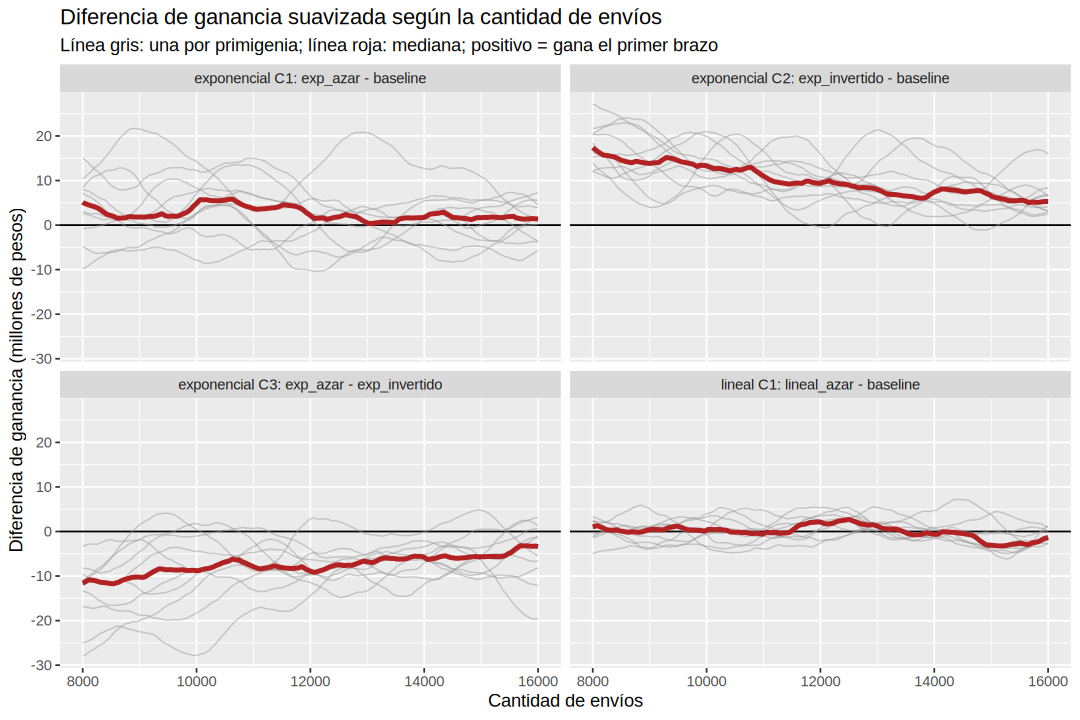

In [18]:
%%R -w 9 -h 6 --units in -r 120
# una fila por primigenia y cantidad de envios, una columna por brazo
ancha_curvas <- dcast(curvas, semilla_primigenia + pos ~ brazo, value.var = "gan_suave_M")

# diferencia pareada de la curva suavizada en las comparaciones disponibles
dif_curvas <- rbindlist(lapply(seq_len(nrow(comparaciones)), function(i) {
  cmp <- comparaciones[i]
  if (!cmp$disponible) return(NULL)
  data.table(comparacion        = paste0(cmp$familia, " ", cmp$codigo, ": ",
                                         cmp$brazo_x, " - ", cmp$brazo_y),
             semilla_primigenia = ancha_curvas$semilla_primigenia,
             envios             = ancha_curvas$pos,
             delta_M            = ancha_curvas[[cmp$brazo_x]] - ancha_curvas[[cmp$brazo_y]])
}))

# tabla en cortes fijos
cortes <- c(9000, 10000, 11000, 12000, 13000, 14000, 15000)
robustez <- dif_curvas[envios %in% cortes,
                       .(n           = .N,
                         n_positivas = sum(delta_M > 0),
                         mediana_M   = median(delta_M),
                         min_M       = min(delta_M),
                         max_M       = max(delta_M)),
                       by = .(comparacion, envios)]
setorder(robustez, comparacion, envios)
print(robustez)

# grafico: diferencia por primigenia a lo largo de los envios
mediana_envios <- dif_curvas[, .(mediana_M = median(delta_M)), by = .(comparacion, envios)]

g4 <- ggplot() +
  geom_hline(yintercept = 0, color = "black") +
  geom_line(data = dif_curvas,
            aes(x = envios, y = delta_M, group = semilla_primigenia),
            color = "grey60", alpha = 0.5, linewidth = 0.4) +
  geom_line(data = mediana_envios,
            aes(x = envios, y = mediana_M),
            color = "firebrick", linewidth = 1.4) +
  facet_wrap(~ comparacion) +
  labs(title = "Diferencia de ganancia suavizada según la cantidad de envíos",
       subtitle = "Línea gris: una por primigenia; línea roja: mediana; positivo = gana el primer brazo",
       x = "Cantidad de envíos", y = "Diferencia de ganancia (millones de pesos)")
print(g4)
ggsave(file.path(dir_plots, "04_diferencias_por_envios.png"), g4, width = 9, height = 6, dpi = 150)

## 9. Conclusiones

La celda genera el texto de las conclusiones a partir de la tabla de resultados, así que se actualiza solo al sumar brazos.

**Lectura con la familia exponencial (25-nov-2026):**

| | Comparación | Positivas | Mediana Δ | p Holm | Lectura |
| :--- | :--- | :--- | :--- | :--- | :--- |
| C1 | Placebo − Baseline | 6 de 10 | +1,14 M | 0,846 | sin diferencia detectada |
| C2 | Invertido − Baseline | 10 de 10 | +7,17 M | 0,006 | mejora |
| C3 | Placebo − Invertido | 0 de 10 | −7,99 M | 0,006 | empeora |

- Tener pesos desiguales sin orden temporal no cambia la ganancia (C1). Darle más peso a los meses viejos la mejora (C2). El orden de los pesos importa (C3).
- Según el criterio fijado en el README, C2 y C3 refutan la hipótesis B en la familia exponencial.
- C3 es la comparación más limpia: sus dos brazos corrieron con el mismo script en las 10 primigenias. En C2, las 5 primigenias de Verónica (pareo limpio) dan 5 de 5 positivas, con mediana +5,3 M.
- **Limitaciones:** un solo mes de testeo (202106), una sola vida media (6 meses), baselines de Fray de otro flujo, y `num_iterations` cerca del borde superior en 3 primigenias.
- **Pendiente:** la familia lineal, que es el experimento principal.

In [19]:
%%R
# texto generado desde 'resultados': se actualiza solo al sumar brazos
cat("\nCONCLUSIONES (generadas a partir de 'resultados')\n")
for (i in seq_len(nrow(resultados))) {
  r <- resultados[i]
  p_aj <- if (is.na(r$p_holm)) "pendiente (faltan comparaciones de la familia)" else sprintf("%.4f", r$p_holm)
  cat(sprintf("%s %s: mediana de la diferencia = %.2f M; %d de %d primigenias positivas; p exacto = %.4f; p ajustado (Holm) = %s; lectura: %s\n",
              r$familia, r$codigo, r$mediana_M, r$n_positivas, r$n, r$p, p_aj, r$lectura))
}


CONCLUSIONES (generadas a partir de 'resultados')
lineal C1: mediana de la diferencia = 1.11 M; 9 de 10 primigenias positivas; p exacto = 0.0195; p ajustado (Holm) = pendiente (faltan comparaciones de la familia); lectura: mejora
exponencial C1: mediana de la diferencia = 1.14 M; 6 de 10 primigenias positivas; p exacto = 0.8457; p ajustado (Holm) = 0.8457; lectura: sin diferencia detectada
exponencial C2: mediana de la diferencia = 7.17 M; 10 de 10 primigenias positivas; p exacto = 0.0020; p ajustado (Holm) = 0.0059; lectura: mejora
exponencial C3: mediana de la diferencia = -7.99 M; 0 de 10 primigenias positivas; p exacto = 0.0020; p ajustado (Holm) = 0.0059; lectura: empeora


## 10. Exportación de tablas y cierre del log

Guarda las tablas en `exp/resultados/tablas/` y cierra el log abierto en la sección 2.

| Archivo | Contenido |
| :--- | :--- |
| `ganancia_por_primigenia_y_brazo.csv` | Tabla pareada: ganancia de cada primigenia en cada brazo |
| `diferencias_pareadas.csv` | Diferencia de cada primigenia en cada comparación |
| `wilcoxon_resultados.csv` | Wilcoxon, Holm, Bonferroni y lectura de cada comparación |
| `descriptivo_por_brazo.csv` | Descriptivo de la ganancia, los envíos y la AUC por brazo |
| `descriptivo_diferencias_por_origen.csv` | Diferencias separadas por quién corrió el baseline |
| `robustez_por_envios.csv` | Diferencias pareadas en cortes fijos de envíos |
| `hiperparametros_y_bordes.csv` | Hiperparámetros elegidos por la BO y corridas contra un borde |

In [20]:
%%R
dir_tablas <- file.path(dir_base, "exp", "resultados", "tablas")
dir.create(dir_tablas, showWarnings = FALSE, recursive = TRUE)

fwrite(ancha,       file.path(dir_tablas, "ganancia_por_primigenia_y_brazo.csv"))
fwrite(diferencias, file.path(dir_tablas, "diferencias_pareadas.csv"))
fwrite(resultados,  file.path(dir_tablas, "wilcoxon_resultados.csv"))
fwrite(desc_brazo,  file.path(dir_tablas, "descriptivo_por_brazo.csv"))
fwrite(desc_dif,    file.path(dir_tablas, "descriptivo_diferencias_por_origen.csv"))
fwrite(robustez,    file.path(dir_tablas, "robustez_por_envios.csv"))
fwrite(desc_hp,     file.path(dir_tablas, "hiperparametros_y_bordes.csv"))

# cierre del log
sink()
cat("Log guardado en:", archivo_log, "\n")
print(list.files(dir_tablas))

Log guardado en: /content/drive/MyDrive/MDM/DM EyF/Experimentos colaborativos/exp/resultados/logs/log_analisis_exp.txt 
[1] "descriptivo_diferencias_por_origen.csv"
[2] "descriptivo_por_brazo.csv"             
[3] "diferencias_pareadas.csv"              
[4] "ganancia_por_primigenia_y_brazo.csv"   
[5] "hiperparametros_y_bordes.csv"          
[6] "robustez_por_envios.csv"               
[7] "wilcoxon_resultados.csv"               
